In [1]:
import os

# os.environ["HF_HOME"] = "/mnt/disks/ai-training/hf_cache"

import math
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as T
import timm
import timm.optim

from scipy.cluster.hierarchy import leaves_list, linkage
from scipy.spatial.distance import squareform
from scipy.stats import spearmanr
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.neighbors import KNeighborsClassifier
from threadpoolctl import threadpool_limits

from lecture_utils import (
    get_device, set_seed, ENCODERS, DATASET_NUM_CLASSES, load_encoder, build_dataset, get_targets,
    extract_features, extract_patch_tokens, PetsSegmentation, masks_to_patch_labels, is_vit,
)

%matplotlib inline
warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", None)

In [2]:
DEVICE = get_device()
NUM_WORKERS = min(16, os.cpu_count() or 4)   # image decoding is the bottleneck of feature extraction
DATA_DIR = "../../data"
FEATURE_DIR = os.path.join(DATA_DIR, "features_lecture3")    # cached features (large, not part of the repo)
RESULTS_DIR = "results"                                       # small result tables (part of the repo)
# Feature extraction for 9 encoders x 3 datasets + fine-tuning runs take ~30 min on an RTX 5090.
# Set to False to skip all computation and plot the precomputed results from `results/`.
RUN_EXPERIMENTS = False
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FEATURE_DIR, exist_ok=True)

set_seed(95431)
print(f"torch {torch.__version__} | timm {timm.__version__} | device: {DEVICE}")

torch 2.11.0 | timm 1.0.30 | device: mps


# Agenda

1. [What is a good representation, and how do we measure it?](#Intro)
2. [Encoders and datasets](#Setup)
3. [k-NN evaluation](#kNN)
4. [Linear probing](#Linear_Probe)
5. [Few-shot evaluation](#Few_Shot)
6. [Fine-tuning: FT vs LP vs LP-FT](#Fine_Tuning)
7. [Where is the information? Layer-wise probing](#Layerwise)
8. [Dense probing: what do patch tokens know?](#Dense)
9. [Looking at embeddings: PCA and t-SNE](#Visualization)
10. [Label-free diagnostics: effective rank and CKA](#Label_Free)
11. [Pitfalls, benchmarks, and how to choose a protocol](#Pitfalls)
12. [Summary and self-check questions](#Summary)

# Resources

**Evaluation protocols**
- [DINO: Emerging Properties in Self-Supervised Vision Transformers (k-NN and linear evaluation protocols; Caron et al., 2021)](https://arxiv.org/abs/2104.14294)
- [DINOv2: Learning Robust Visual Features without Supervision (frozen-feature evaluation suite; Oquab et al., 2023)](https://arxiv.org/abs/2304.07193) and [DINOv3 (2025)](https://arxiv.org/abs/2508.10104)
- [Masked Autoencoders Are Scalable Vision Learners (linear probe vs fine-tuning; He et al., 2021)](https://arxiv.org/abs/2111.06377)
- [Do Better ImageNet Models Transfer Better? (Kornblith et al., 2019)](https://arxiv.org/abs/1805.08974)
- [A Large-scale Study of Representation Learning with the Visual Task Adaptation Benchmark (VTAB; Zhai et al., 2019)](https://arxiv.org/abs/1910.04867)
- [How Well Do Self-Supervised Models Transfer? (Ericsson et al., 2021)](https://arxiv.org/abs/2011.13377)
- [Fine-Tuning can Distort Pretrained Features and Underperform Out-of-Distribution (LP-FT; Kumar et al., 2022)](https://arxiv.org/abs/2202.10054)

**Representation analysis**
- [Similarity of Neural Network Representations Revisited (CKA; Kornblith et al., 2019)](https://arxiv.org/abs/1905.00414)
- [RankMe: Assessing the Downstream Performance of Pretrained Self-Supervised Representations by Their Rank (Garrido et al., 2023)](https://arxiv.org/abs/2210.02885)
- [Understanding Contrastive Representation Learning through Alignment and Uniformity (Wang & Isola, 2020)](https://arxiv.org/abs/2005.10242)
- [Visualizing Data using t-SNE (van der Maaten & Hinton, 2008)](https://www.jmlr.org/papers/v9/vandermaaten08a.html) and [How to Use t-SNE Effectively (Distill, 2016)](https://distill.pub/2016/misread-tsne/)
- [The Platonic Representation Hypothesis (Huh et al., 2024)](https://arxiv.org/abs/2405.07987)

**Data**
- [Oxford-IIIT Pets](https://www.robots.ox.ac.uk/~vgg/data/pets/), [Oxford Flowers-102](https://www.robots.ox.ac.uk/~vgg/data/flowers/102/), [Describable Textures Dataset](https://www.robots.ox.ac.uk/~vgg/data/dtd/)

<a id='Intro'></a>
# What is a good representation, and how do we measure it?

A pretrained encoder $f_\theta$ maps an image $x$ to a **representation** $z = f_\theta(x)$: a global vector (the [CLS] token or the average of the patch tokens) and, for ViTs, a grid of patch tokens. In Lectures 1–2 we trained and compared encoders by their **ImageNet accuracy**. But most encoders today are trained **without** the labels of the task we care about (self-supervised, image-text, or on a different label set), and are reused for many different tasks. So we need a different question:

> **How useful is $z$ for tasks the encoder was not trained on?**

There is no single answer — "useful" depends on how much we are willing to adapt the encoder. Evaluation protocols differ in **what is trained** on top of the frozen (or not) encoder:

| Protocol | What is trained | Cost | What it measures |
|---|---|---|---|
| **k-NN** | nothing | lowest | do images of the same class lie close to each other? |
| **Linear probe** | one linear layer | low | is the class information *linearly* readable from $z$? |
| **Few-shot** (k-NN / linear) | as above, on 1–10 images per class | low | data efficiency of the representation |
| **Layer-wise probe** | linear layers on intermediate blocks | low | where in the network the information lives |
| **Dense (patch) probe** | linear layer on every patch token | low | spatial information for segmentation / depth |
| **Fine-tuning** (full, partial, LP-FT) | the whole network | high | how good the encoder is as an **initialization** |
| **Label-free diagnostics** (effective rank, CKA, visualization) | nothing, no labels | lowest | geometry of the embedding space, similarity between models |

A central message of this lecture: **different protocols can rank the same encoders differently**. A representation that is excellent for k-NN may be mediocre for fine-tuning and vice versa. Always state the protocol together with the number.

<a id='Setup'></a>
# Encoders and datasets

## Nine encoders with different pre-training

All encoders come from `timm`. We use small models (ViT-S, ~22M parameters) where possible; MAE and CLIP are only available as ViT-B (~86M) — keep the size difference in mind when comparing.

In [3]:
pd.DataFrame(
    [{"encoder": name, "timm checkpoint": ckpt, "pre-training": pretraining} for name, (ckpt, pretraining, _) in ENCODERS.items()]
)

,encoder,timm checkpoint,pre-training
0,Random ViT-S/16,vit_small_patch16_224,random init (lower bound)
1,"ResNet-50 (sup, IN-1k)",resnet50.a1_in1k,"supervised, ImageNet-1k"
2,"ViT-S/16 (sup, IN-1k)",vit_small_patch16_224.augreg_in1k,"supervised, ImageNet-1k"
3,"ViT-S/16 (sup, IN-21k)",vit_small_patch16_224.augreg_in21k,"supervised, ImageNet-21k"
4,ViT-S/16 (DINO),vit_small_patch16_224.dino,"self-supervised, ImageNet-1k"
5,ViT-S/14 (DINOv2-reg),vit_small_patch14_reg4_dinov2.lvd142m,"self-supervised, LVD-142M"
6,ViT-S/16 (DINOv3),vit_small_patch16_dinov3.lvd1689m,"self-supervised, LVD-1689M"
7,ViT-B/16 (MAE),vit_base_patch16_224.mae,"self-supervised (masked), ImageNet-1k"
8,ViT-B/16 (CLIP),vit_base_patch16_clip_224.openai,"image-text, 400M pairs"


## Three downstream datasets

| Dataset | Classes | Train / val / test | Why |
|---|---|---|---|
| **Oxford-IIIT Pets** | 37 cat and dog breeds | 2944 / 736 / 3669 (val = 20% of the official trainval) | fine-grained natural images, similar to ImageNet; also has pixel masks (used for dense probing) |
| **Flowers-102** | 102 flower species | 1020 / 1020 / 6149 | fine-grained, only **10** training images per class |
| **DTD** (textures) | 47 texture types ("striped", "bubbly", …) | 1880 / 1880 / 1880 | far from object-centric ImageNet: tests how *general* the features are |

All images are resized and center-cropped to $224 \times 224$ with the normalization each checkpoint expects. The images come from HuggingFace Hub mirrors with the official splits (`timm/oxford-iiit-pet`, `dpdl-benchmark/oxford_flowers102`, `dpdl-benchmark/dtd`) — the original Oxford servers are often very slow; only the small Pets mask archive (~19 MB) is downloaded from Oxford.

In [4]:
DATASETS = ["pets", "flowers", "dtd"]

if RUN_EXPERIMENTS:
    fig, axes = plt.subplots(3, 8, figsize=(16, 6.5))
    for row, name in enumerate(DATASETS):
        ds = build_dataset(name, "test", transform=None, root=DATA_DIR)
        classes = getattr(ds, "classes", None)
        for ax, i in zip(axes[row], np.random.default_rng(0).choice(len(ds), 8, replace=False)):
            img, label = ds[i]
            ax.imshow(img)
            ax.set_title(classes[label][:18] if classes else f"class {label}", fontsize=8)
            ax.axis("off")
    plt.suptitle("Pets / Flowers-102 / DTD")
    plt.tight_layout()
    plt.show()

## Extracting frozen features once

All frozen-encoder protocols (k-NN, linear, few-shot, label-free) only need the features, so we run each encoder **once** over every split and cache:

* `cls` — the [CLS] token after the final LayerNorm (for the CNN: global average pooling),
* `gap` — the average of the patch tokens after the final LayerNorm,
* for four encoders on Pets also the pooled outputs of **every block** (for layer-wise probing).

> ⏱️ ~5 minutes on an RTX 5090 for 9 encoders × 3 datasets × 3 splits (≈ 22k images per encoder). The cache lives in `../../data/features_lecture3` (not in the repo).

In [5]:
LAYERWISE_ENCODERS = ["ViT-S/16 (sup, IN-1k)", "ViT-S/16 (DINOv3)", "ViT-B/16 (MAE)", "ViT-B/16 (CLIP)"]


def feature_path(encoder, dataset, split):
    safe = encoder.replace("/", "-").replace(" ", "_").replace("(", "").replace(")", "").replace(",", "")
    return os.path.join(FEATURE_DIR, f"{safe}__{dataset}__{split}.pt")


def load_feats(encoder, dataset, split):
    return torch.load(feature_path(encoder, dataset, split))


if RUN_EXPERIMENTS:
    start = time.time()
    for enc in ENCODERS:
        model, transform = load_encoder(enc, DEVICE)
        for ds_name in DATASETS:
            for split in ("train", "val", "test"):
                path = feature_path(enc, ds_name, split)
                if os.path.exists(path):
                    continue
                ds = build_dataset(ds_name, split, transform, root=DATA_DIR)
                layers = list(range(len(model.blocks))) if (enc in LAYERWISE_ENCODERS and ds_name == "pets") else None
                torch.save(extract_features(model, ds, DEVICE, num_workers=NUM_WORKERS, layers=layers), path)
        print(f"{enc:<26} done ({(time.time() - start) / 60:.1f} min)")
        del model
    f = load_feats("ViT-S/16 (DINOv3)", "pets", "train")
    print({k: tuple(v.shape) for k, v in f.items()})

<a id='kNN'></a>
# k-NN evaluation

The simplest protocol trains **nothing**. For a test image we find its $k$ nearest training images in the embedding space and let them vote. We use the weighted variant from DINO, which became the standard for self-supervised models:

1. L2-normalize all embeddings, so that the dot product is the **cosine similarity** $s_i = \cos(z, z_i)$.
2. Take the $k$ most similar training embeddings ($k = 20$).
3. Each neighbour votes for its class with weight $\exp(s_i / \tau)$, $\tau = 0.07$: closer neighbours count more.

$$
\hat{y} = \arg\max_c \sum_{i \in \mathcal{N}_k(z)} \exp(s_i/\tau)\, \mathbb{1}[y_i = c].
$$

**What it measures:** whether the encoder already places images of the same class close together. It has no trainable parameters, so it cannot "fix" the representation — and it is very sensitive to the **geometry** of the space (one dominant direction, a few huge-norm dimensions, or an unused [CLS] token immediately hurt it). Encoders trained to pull similar images together (contrastive or self-distillation objectives) tend to look especially good under k-NN.

In [6]:
@torch.no_grad()
def knn_classify(train_x, train_y, test_x, num_classes, k=20, T=0.07, batch_size=1024):
    """Weighted k-NN on cosine similarity (DINO protocol). Returns predicted labels for test_x."""
    train_x, test_x = F.normalize(train_x.float(), dim=1), F.normalize(test_x.float(), dim=1)
    k = min(k, len(train_x))
    preds = []
    for i in range(0, len(test_x), batch_size):
        sims = test_x[i:i + batch_size] @ train_x.T                    # (b, N_train) cosine similarities
        top_sims, top_idx = sims.topk(k, dim=1)
        weights = (top_sims / T).exp()
        votes = torch.zeros(len(sims), num_classes, device=sims.device)
        votes.scatter_add_(1, train_y[top_idx], weights)               # sum of weights per class
        preds.append(votes.argmax(dim=1))
    return torch.cat(preds)


# Sanity check against scikit-learn: with a huge temperature all weights are equal -> plain majority vote
rng = np.random.default_rng(0)
Xtr, Xte = rng.normal(size=(500, 16)).astype("float32"), rng.normal(size=(200, 16)).astype("float32")
ytr = rng.integers(0, 5, 500)
ours = knn_classify(torch.tensor(Xtr), torch.tensor(ytr), torch.tensor(Xte), 5, k=15, T=1e6).numpy()
sk = KNeighborsClassifier(n_neighbors=15, metric="cosine").fit(Xtr, ytr).predict(Xte)
print(f"agreement with sklearn (uniform weights): {(ours == sk).mean():.3f}")

agreement with sklearn (uniform weights): 0.935


In [7]:
def default_pooling(encoder):
    """The 'default' global representation used in the main tables: [CLS] for ViTs, average pooling for the CNN."""
    return "gap" if encoder.startswith("ResNet") else "cls"


def get_split(encoder, dataset, split, pooling=None, device=DEVICE):
    f = load_feats(encoder, dataset, split)
    pooling = pooling or default_pooling(encoder)
    return f[pooling].to(device), f["y"].long().to(device)


knn_path = os.path.join(RESULTS_DIR, "knn_results.csv")
if RUN_EXPERIMENTS and not os.path.exists(knn_path):   # skip if already computed
    rows = []
    for enc in ENCODERS:
        for ds_name in DATASETS:
            x_tr, y_tr = get_split(enc, ds_name, "train")
            x_va, y_va = get_split(enc, ds_name, "val")
            x_te, y_te = get_split(enc, ds_name, "test")
            x_trval, y_trval = torch.cat([x_tr, x_va]), torch.cat([y_tr, y_va])
            pred = knn_classify(x_trval, y_trval, x_te, DATASET_NUM_CLASSES[ds_name])
            rows.append({"encoder": enc, "dataset": ds_name, "knn_acc": (pred == y_te).float().mean().item()})
    pd.DataFrame(rows).to_csv(knn_path, index=False)
knn_df = pd.read_csv(knn_path)
knn_table = knn_df.pivot(index="encoder", columns="dataset", values="knn_acc").loc[list(ENCODERS), DATASETS]
knn_table.style.format("{:.1%}").background_gradient(axis=0, cmap="Greens")

dataset,pets,flowers,dtd
encoder,,,
Random ViT-S/16,6.0%,13.5%,11.9%
"ResNet-50 (sup, IN-1k)",91.2%,74.3%,71.9%
"ViT-S/16 (sup, IN-1k)",90.5%,74.3%,69.3%
"ViT-S/16 (sup, IN-21k)",90.4%,98.9%,76.3%
ViT-S/16 (DINO),91.5%,88.3%,75.3%
ViT-S/14 (DINOv2-reg),93.4%,99.6%,79.4%
ViT-S/16 (DINOv3),93.4%,99.4%,80.3%
ViT-B/16 (MAE),19.3%,21.9%,26.8%
ViT-B/16 (CLIP),85.2%,91.1%,71.5%


### How sensitive is k-NN to $k$?

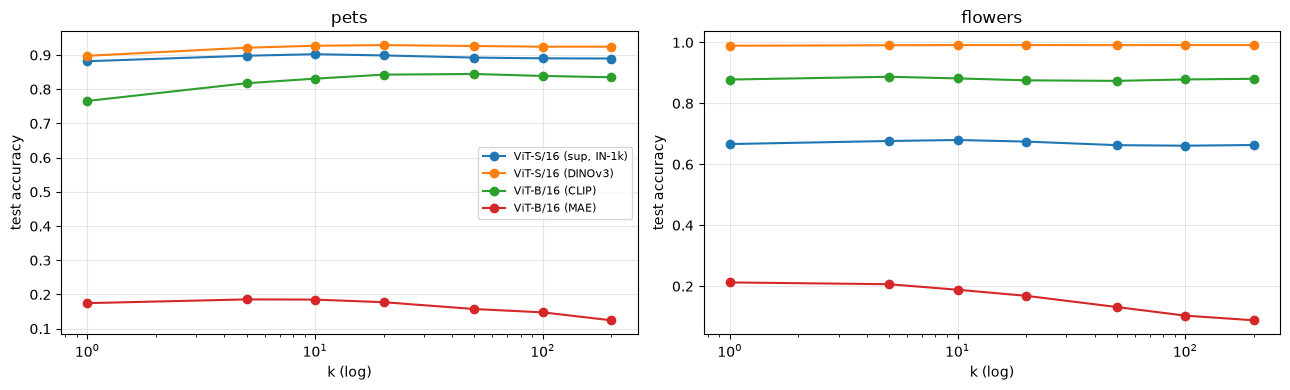

In [8]:
ksweep_path = os.path.join(RESULTS_DIR, "knn_k_sweep.csv")
KSWEEP_ENCODERS = ["ViT-S/16 (sup, IN-1k)", "ViT-S/16 (DINOv3)", "ViT-B/16 (CLIP)", "ViT-B/16 (MAE)"]
if RUN_EXPERIMENTS and not os.path.exists(ksweep_path):   # skip if already computed
    rows = []
    for enc in KSWEEP_ENCODERS:
        for ds_name in ["pets", "flowers"]:
            x_tr, y_tr = get_split(enc, ds_name, "train")
            x_te, y_te = get_split(enc, ds_name, "test")
            for k in [1, 5, 10, 20, 50, 100, 200]:
                pred = knn_classify(x_tr, y_tr, x_te, DATASET_NUM_CLASSES[ds_name], k=k)
                rows.append({"encoder": enc, "dataset": ds_name, "k": k, "acc": (pred == y_te).float().mean().item()})
    pd.DataFrame(rows).to_csv(ksweep_path, index=False)
ks = pd.read_csv(ksweep_path)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, ds_name in zip(axes, ["pets", "flowers"]):
    for enc in KSWEEP_ENCODERS:
        d = ks[(ks.encoder == enc) & (ks.dataset == ds_name)]
        ax.plot(d.k, d.acc, marker="o", label=enc)
    ax.set_xscale("log"); ax.set_xlabel("k (log)"); ax.set_ylabel("test accuracy"); ax.set_title(ds_name)
    ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

### Takeaways (k-NN)

* The self-supervised **DINOv2 / DINOv3** encoders give the best k-NN accuracy on all three datasets (~93% Pets, >99% Flowers, ~80% DTD): their training objective explicitly pulls similar images together.
* The supervised ViT-S pre-trained on **ImageNet-21k** gets 98.9% on Flowers versus 74% for the ImageNet-1k version: ImageNet-21k contains many flower categories. Pre-training *label* overlap inflates transfer numbers (see Pitfalls).
* **MAE is almost at chance** under k-NN (19% on Pets) — its global embedding is a poor metric space. The information is there, as the linear probe will show.
* Accuracy is flat for $k$ between ~10 and 50, so the DINO default $k = 20$ is safe. For MAE more neighbours only add noise.

<a id='Linear_Probe'></a>
# Linear probing

A **linear probe** freezes the encoder and trains a single linear layer (multinomial logistic regression) on top:

$$
\hat{y} = \arg\max_c\, (W z + b)_c, \qquad \min_{W, b}\ \frac{1}{N}\sum_i \mathrm{CE}(W z_i + b,\, y_i) + \lambda \lVert W \rVert_2^2 .
$$

It asks: **is the class information linearly readable** from the representation? Unlike k-NN it can re-weight and ignore dimensions, so it is robust to the scale and shape of the embedding space; unlike fine-tuning it cannot create information that is not already there.

## A clean protocol

The details matter more than people expect — different papers use different recipes, and numbers are only comparable under the same one:

1. **Standardize** the features with the mean and std of the training set (logistic regression is sensitive to feature scale).
2. Choose the regularization strength $\lambda$ on a **validation** split — never on the test set.
3. Refit on train + val with the chosen $\lambda$, report test accuracy **once**.
4. The problem is convex, so we solve it to convergence with full-batch **L-BFGS** — deterministic and fast on a GPU. (DINO / MAE use SGD with data augmentation and many epochs instead; numbers from the two recipes are not directly comparable.)

In [9]:
def fit_logreg(x, y, num_classes, weight_decay, max_iter=300):
    """Multinomial logistic regression with L2 penalty, solved by full-batch L-BFGS."""
    torch.manual_seed(0)
    clf = nn.Linear(x.shape[1], num_classes).to(x.device)
    opt = torch.optim.LBFGS(clf.parameters(), lr=1.0, max_iter=max_iter, history_size=20,
                            line_search_fn="strong_wolfe", tolerance_grad=1e-6, tolerance_change=1e-9)

    def closure():
        opt.zero_grad()
        loss = F.cross_entropy(clf(x), y) + weight_decay * clf.weight.pow(2).sum()
        loss.backward()
        return loss

    opt.step(closure)
    return clf


def standardize(train, *others):
    mean, std = train.mean(0, keepdim=True), train.std(0, keepdim=True).clamp_min(1e-6)
    return [(t - mean) / std for t in (train, *others)]


def linear_probe(train, val, test, num_classes, weight_decays=(1e-5, 1e-4, 1e-3, 1e-2, 1e-1)):
    """train/val/test = (x, y). Selects weight decay on val, refits on train+val, returns test accuracy."""
    (x_tr, y_tr), (x_va, y_va), (x_te, y_te) = train, val, test
    xs_tr, xs_va = standardize(x_tr, x_va)
    val_acc = {}
    for wd in weight_decays:
        clf = fit_logreg(xs_tr, y_tr, num_classes, wd)
        with torch.no_grad():
            val_acc[wd] = (clf(xs_va).argmax(1) == y_va).float().mean().item()
    best_wd = max(val_acc, key=val_acc.get)
    xs_trval, xs_te = standardize(torch.cat([x_tr, x_va]), x_te)
    clf = fit_logreg(xs_trval, torch.cat([y_tr, y_va]), num_classes, best_wd)
    with torch.no_grad():
        test_acc = (clf(xs_te).argmax(1) == y_te).float().mean().item()
    return {"test_acc": test_acc, "best_wd": best_wd, "best_val_acc": val_acc[best_wd]}


# Sanity check on synthetic, linearly separable data
g = torch.Generator().manual_seed(0)
centers = torch.randn(4, 32, generator=g) * 3
make = lambda n: (lambda y: (centers[y] + torch.randn(n, 32, generator=g), y))(torch.randint(0, 4, (n,), generator=g))
res = linear_probe(make(400), make(200), make(400), num_classes=4)
print(res)

{'test_acc': 1.0, 'best_wd': 1e-05, 'best_val_acc': 1.0}


In [10]:
lp_path = os.path.join(RESULTS_DIR, "linear_probe_results.csv")
if RUN_EXPERIMENTS and not os.path.exists(lp_path):   # skip if already computed
    rows = []
    for enc in ENCODERS:
        for ds_name in DATASETS:
            res = linear_probe(get_split(enc, ds_name, "train"), get_split(enc, ds_name, "val"),
                               get_split(enc, ds_name, "test"), DATASET_NUM_CLASSES[ds_name])
            rows.append({"encoder": enc, "dataset": ds_name, "lp_acc": res["test_acc"], "best_wd": res["best_wd"]})
    pd.DataFrame(rows).to_csv(lp_path, index=False)
lp_df = pd.read_csv(lp_path)
lp_table = lp_df.pivot(index="encoder", columns="dataset", values="lp_acc").loc[list(ENCODERS), DATASETS]
lp_table.style.format("{:.1%}").background_gradient(axis=0, cmap="Blues")

dataset,pets,flowers,dtd
encoder,,,
Random ViT-S/16,8.6%,25.0%,16.0%
"ResNet-50 (sup, IN-1k)",92.5%,86.7%,72.0%
"ViT-S/16 (sup, IN-1k)",91.6%,88.3%,70.5%
"ViT-S/16 (sup, IN-21k)",93.0%,99.7%,78.6%
ViT-S/16 (DINO),93.6%,96.5%,77.4%
ViT-S/14 (DINOv2-reg),94.7%,99.7%,79.7%
ViT-S/16 (DINOv3),94.7%,99.5%,81.1%
ViT-B/16 (MAE),82.3%,87.4%,72.2%
ViT-B/16 (CLIP),92.4%,97.3%,78.5%


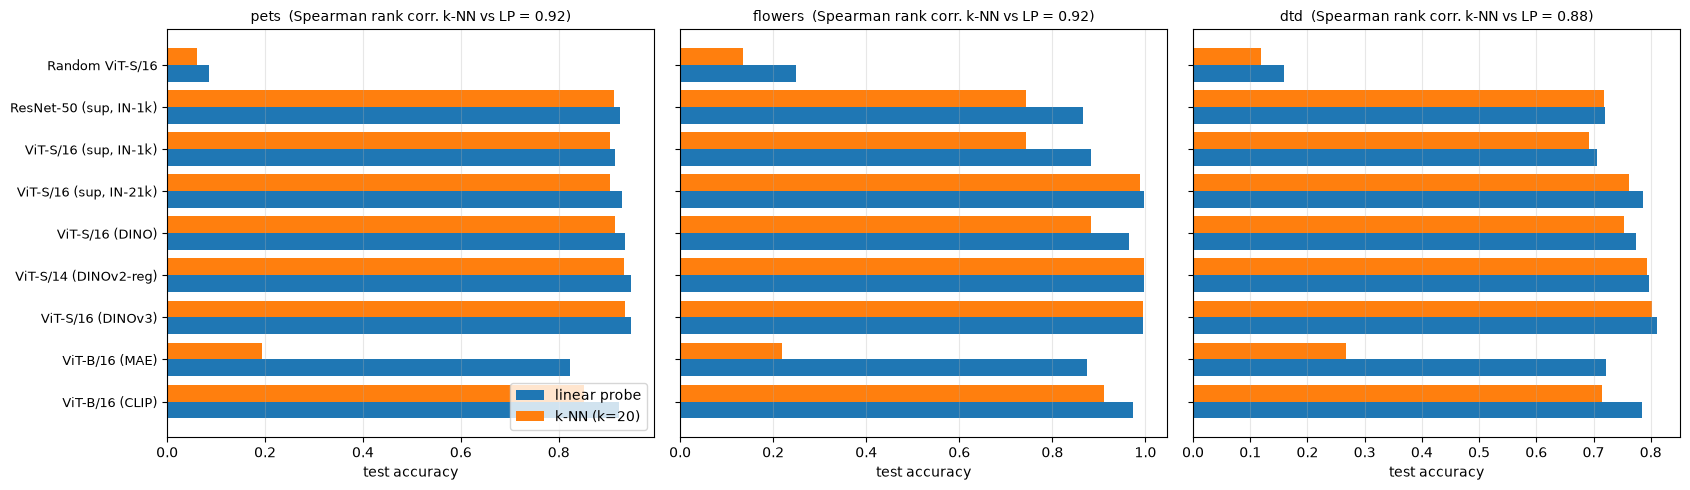

In [11]:
both = knn_df.merge(lp_df, on=["encoder", "dataset"])
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharey=True)
for ax, ds_name in zip(axes, DATASETS):
    d = both[both.dataset == ds_name].set_index("encoder").loc[list(ENCODERS)]
    pos = np.arange(len(d))
    ax.barh(pos + 0.2, d.lp_acc, height=0.4, label="linear probe")
    ax.barh(pos - 0.2, d.knn_acc, height=0.4, label="k-NN (k=20)")
    ax.set_yticks(pos); ax.set_yticklabels(d.index, fontsize=9); ax.invert_yaxis()
    rho = spearmanr(d.knn_acc, d.lp_acc).correlation
    ax.set_title(f"{ds_name}  (Spearman rank corr. k-NN vs LP = {rho:.2f})", fontsize=10)
    ax.set_xlabel("test accuracy"); ax.grid(alpha=0.3, axis="x")
axes[0].legend(loc="lower right")
plt.tight_layout()
plt.show()

### Takeaways (linear probe)

* The linear probe is never worse than k-NN and closes most of the gap for encoders with a poor geometry: **MAE goes from 19% (k-NN) to 82% (linear) on Pets**. A linear layer on standardized features can re-weight the few dimensions that carry the information; cosine similarity cannot.
* Apart from MAE, the k-NN and linear rankings agree well (Spearman 0.88–0.92): for well-behaved embeddings k-NN is a cheap, reliable proxy.
* The best frozen features come from **DINOv3 / DINOv2 at ViT-S size**, matching or beating the 4x larger CLIP ViT-B. Supervised IN-21k is competitive on object-like data (Pets, Flowers) and slightly behind on textures (DTD).

## Which global vector? [CLS] vs average of patch tokens

So far every ViT was represented by its [CLS] token. But which global vector carries the information depends on what the pre-training objective **used**. Let's compare three choices on every dataset: [CLS], the average of the patch tokens (GAP), and their concatenation (the DINO recipe).

In [12]:
pool_path = os.path.join(RESULTS_DIR, "pooling_comparison.csv")
VIT_ENCODERS = [e for e in ENCODERS if not e.startswith("ResNet")]
if RUN_EXPERIMENTS and not os.path.exists(pool_path):   # skip if already computed
    rows = []
    for enc in VIT_ENCODERS:
        for ds_name in DATASETS:
            splits = {s: load_feats(enc, ds_name, s) for s in ("train", "val", "test")}
            for pooling in ("cls", "gap", "cls+gap"):
                def xy(s):
                    f = splits[s]
                    x = torch.cat([f["cls"], f["gap"]], 1) if pooling == "cls+gap" else f[pooling]
                    return x.to(DEVICE), f["y"].long().to(DEVICE)
                res = linear_probe(xy("train"), xy("val"), xy("test"), DATASET_NUM_CLASSES[ds_name])
                rows.append({"encoder": enc, "dataset": ds_name, "pooling": pooling, "lp_acc": res["test_acc"]})
    pd.DataFrame(rows).to_csv(pool_path, index=False)
pool_df = pd.read_csv(pool_path)
pool_table = pool_df.pivot_table(index=["encoder"], columns=["dataset", "pooling"], values="lp_acc").loc[VIT_ENCODERS]
pool_table.style.format("{:.1%}").background_gradient(axis=1, cmap="Blues")

### Takeaways (pooling)

* For **DINO, DINOv2 and DINOv3** the [CLS] token is clearly better than the patch average (DINO on Pets: 94% vs 76%): the self-distillation loss is applied to [CLS], so that is where the global information is concentrated.
* For supervised and CLIP models the choice matters little (1–2 points), and the concatenation is usually as good as the best single choice.
* MAE is mediocre with both; the concatenation helps a little.
* Lesson: always report the pooling, and choose it on the validation set — the wrong choice can cost almost 20 points.

<a id='Few_Shot'></a>
# Few-shot evaluation

In practice labels are expensive. A representation is valuable if a classifier on top needs **few** labelled examples. We sample $n \in \{1, 2, 5, 10\}$ training images per class (3 random seeds), fit a k-NN and a linear probe, and evaluate on the full test set. Without a validation set we keep the weight decay that the encoder's full-data probe selected.

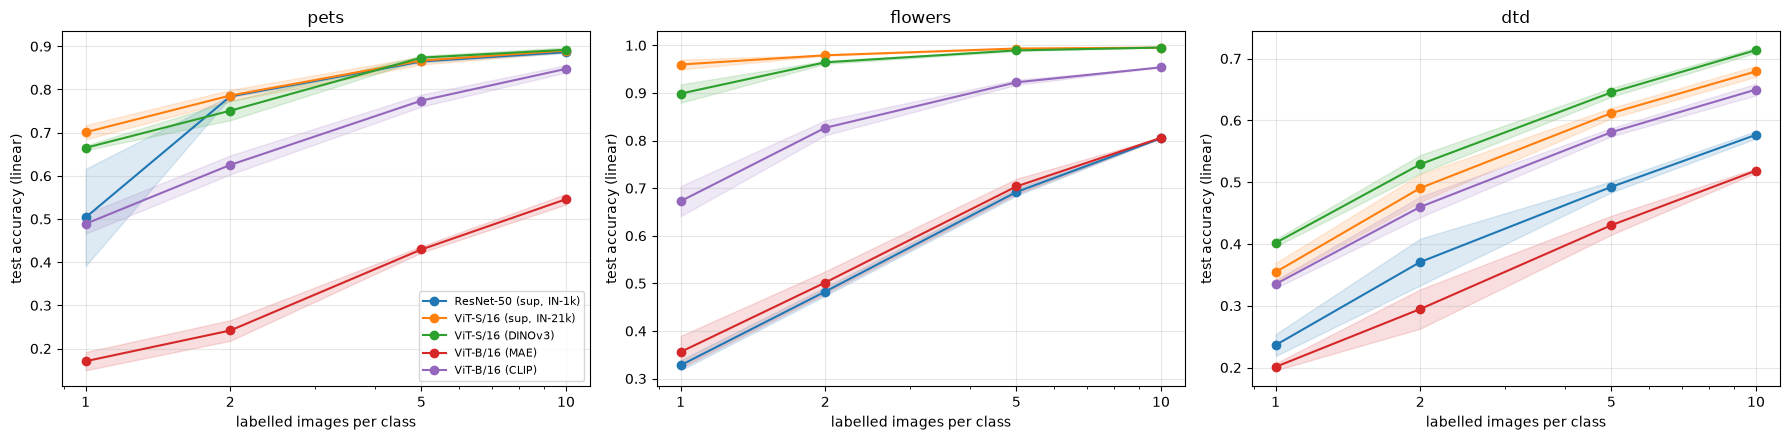

In [13]:
def few_shot_indices(y, n_per_class, seed):
    rng = np.random.default_rng(seed)
    y = np.asarray(y)
    return np.concatenate([rng.choice(np.flatnonzero(y == c), min(n_per_class, (y == c).sum()), replace=False)
                           for c in np.unique(y)])


FEWSHOT_ENCODERS = ["ResNet-50 (sup, IN-1k)", "ViT-S/16 (sup, IN-21k)", "ViT-S/16 (DINOv3)", "ViT-B/16 (MAE)", "ViT-B/16 (CLIP)"]
fewshot_path = os.path.join(RESULTS_DIR, "few_shot.csv")
if RUN_EXPERIMENTS and not os.path.exists(fewshot_path):   # skip if already computed
    rows = []
    for enc in FEWSHOT_ENCODERS:
        for ds_name in DATASETS:
            nc = DATASET_NUM_CLASSES[ds_name]
            x_tr, y_tr = get_split(enc, ds_name, "train")
            x_te, y_te = get_split(enc, ds_name, "test")
            wd = lp_df[(lp_df.encoder == enc) & (lp_df.dataset == ds_name)].best_wd.item()
            for n in [1, 2, 5, 10]:
                for seed in range(3):
                    idx = torch.as_tensor(few_shot_indices(y_tr.cpu(), n, seed), device=DEVICE)
                    xs, ys = x_tr[idx], y_tr[idx]
                    knn_acc = (knn_classify(xs, ys, x_te, nc) == y_te).float().mean().item()
                    xs_std, xte_std = standardize(xs, x_te)
                    clf = fit_logreg(xs_std, ys, nc, wd)
                    with torch.no_grad():
                        lin_acc = (clf(xte_std).argmax(1) == y_te).float().mean().item()
                    rows.append({"encoder": enc, "dataset": ds_name, "shots": n, "seed": seed,
                                 "knn": knn_acc, "linear": lin_acc})
    pd.DataFrame(rows).to_csv(fewshot_path, index=False)
fs = pd.read_csv(fewshot_path)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, ds_name in zip(axes, DATASETS):
    for enc in FEWSHOT_ENCODERS:
        d = fs[(fs.encoder == enc) & (fs.dataset == ds_name)].groupby("shots")
        m, s = d.linear.mean(), d.linear.std()
        line, = ax.plot(m.index, m.values, marker="o", label=enc)
        ax.fill_between(m.index, m - s, m + s, alpha=0.15, color=line.get_color())
    ax.set_xscale("log"); ax.set_xticks([1, 2, 5, 10]); ax.set_xticklabels([1, 2, 5, 10])
    ax.set_xlabel("labelled images per class"); ax.set_ylabel("test accuracy (linear)"); ax.set_title(ds_name)
    ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

### Takeaways (few-shot)

* With **one** labelled image per class, DINOv3 and supervised IN-21k already reach 66–70% on Pets and 90–96% on Flowers; CLIP needs more examples; frozen MAE features are useless in this regime (17% with one shot on Pets).
* The ranking changes with the number of labels: on Pets, ResNet-50 with k-NN is the best 1-shot model (77%) — ImageNet-1k itself contains over a hundred dog breeds and several cat breeds, so its features already separate them.
* The spread between seeds (shaded) is usually 1–3 points, but can be huge: ±11 points for ResNet-50's linear probe with one shot (a 2048-d linear layer and a standardization estimated from 37 images). Few-shot numbers need several seeds.

<a id='Fine_Tuning'></a>
# Fine-tuning: FT vs LP vs LP-FT

Frozen protocols measure what the representation **already** contains. Fine-tuning measures how good the encoder is as a **starting point** when we are allowed to change all its weights. Three variants on Oxford-IIIT Pets, all for the same number of epochs and with the same augmentation:

* **LP** — train only the linear head (the backbone stays frozen) — an "online" linear probe with augmentation;
* **FT** — train everything from the start; the new head is randomly initialized;
* **LP-FT** (Kumar et al., 2022) — first train only the head (a few epochs), then fine-tune everything.

**Why LP-FT?** At the start of FT the head is random, so the first gradients that reach the backbone are essentially noise — they push the pretrained features in arbitrary directions ("feature distortion"), especially in the first steps when the loss is large. If the head is already good, the backbone receives meaningful gradients from step one and, according to Kumar et al., its features change less. They show this helps most **out of distribution**, but it is a cheap trick to know in general. Let's check both claims.

The FT recipe is the one from Lecture 1: AdamW, warmup + cosine, layer-wise learning-rate decay (0.75), stochastic depth 0.1, bf16. To quantify **how much the features changed**, we compute the linear CKA (see the "Label-free diagnostics" section) between the encoder's pooled features before and after training: 1.0 = unchanged.

In [14]:
def linear_cka(x, y):
    """Linear CKA between two representations of the same N examples: x (N, D1), y (N, D2)."""
    x = x.double() - x.double().mean(0, keepdim=True)
    y = y.double() - y.double().mean(0, keepdim=True)
    hsic = (x.T @ y).pow(2).sum()
    return (hsic / ((x.T @ x).pow(2).sum().sqrt() * (y.T @ y).pow(2).sum().sqrt())).item()


@torch.no_grad()
def pooled_features(model, loader):
    model.eval()
    out = []
    for x, _ in loader:
        with torch.autocast(device_type=DEVICE, dtype=torch.bfloat16, enabled=DEVICE in ("cuda", "mps")):
            out.append(model.forward_head(model.forward_features(x.to(DEVICE)), pre_logits=True).float().cpu())
    return torch.cat(out)


@torch.no_grad()
def accuracy(model, loader):
    model.eval()
    correct, total = 0, 0
    for x, y in loader:
        with torch.autocast(device_type=DEVICE, dtype=torch.bfloat16, enabled=DEVICE in ("cuda", "mps")):
            correct += (model(x.to(DEVICE)).argmax(1).cpu() == y).sum().item()
        total += len(y)
    return correct / total


def train_stage(model, loader, epochs, lr, train_backbone, weight_decay=0.05, layer_decay=0.75):
    """One training stage with warmup (1 epoch) + cosine. If train_backbone=False only the head is trained."""
    head_params = set(id(p) for p in model.get_classifier().parameters())
    for p in model.parameters():
        p.requires_grad = train_backbone or id(p) in head_params
    if train_backbone:
        groups = timm.optim.param_groups_layer_decay(model, weight_decay=weight_decay, layer_decay=layer_decay,
                                                     no_weight_decay_list=model.no_weight_decay())
        for g in groups:
            g["lr"] = lr * g.pop("lr_scale", 1.0)
    else:
        groups = [{"params": list(model.get_classifier().parameters()), "lr": lr, "weight_decay": weight_decay}]
    opt = torch.optim.AdamW(groups, lr=lr, betas=(0.9, 0.999))
    total, warmup = epochs * len(loader), len(loader)
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: (s + 1) / warmup if s < warmup else 0.5 * (1 + math.cos(math.pi * (s - warmup) / max(1, total - warmup))))
    for _ in range(epochs):
        model.train()
        for x, y in loader:
            with torch.autocast(device_type=DEVICE, dtype=torch.bfloat16, enabled=DEVICE in ("cuda", "mps")):
                loss = F.cross_entropy(model(x.to(DEVICE)), y.to(DEVICE), label_smoothing=0.1)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            sched.step()


def run_fine_tuning(encoder, mode, epochs=15, lp_epochs=5, lr=1e-4, head_lr=1e-3, batch_size=64):
    set_seed(95431)
    ckpt, _, kwargs = ENCODERS[encoder]
    model = timm.create_model(ckpt, pretrained=True, num_classes=37, drop_path_rate=0.1, **kwargs).to(DEVICE)
    cfg = timm.data.resolve_data_config({"input_size": (3, 224, 224)}, model=model)
    train_tf = T.Compose([T.RandomResizedCrop(224, scale=(0.35, 1.0), interpolation=T.InterpolationMode.BICUBIC),
                          T.RandomHorizontalFlip(), T.ToTensor(), T.Normalize(cfg["mean"], cfg["std"])])
    eval_tf = timm.data.create_transform(**cfg)
    kw = dict(num_workers=NUM_WORKERS, pin_memory=DEVICE == "cuda")
    train_loader = torch.utils.data.DataLoader(build_dataset("pets", "trainval", train_tf, DATA_DIR), batch_size,
                                               shuffle=True, drop_last=True, **kw)
    test_loader = torch.utils.data.DataLoader(build_dataset("pets", "test", eval_tf, DATA_DIR), 128, **kw)
    feats_before = pooled_features(model, test_loader)

    start = time.time()
    if mode == "LP":
        train_stage(model, train_loader, epochs, head_lr, train_backbone=False)
    elif mode == "FT":
        train_stage(model, train_loader, epochs, lr, train_backbone=True)
    elif mode == "LP-FT":
        train_stage(model, train_loader, lp_epochs, head_lr, train_backbone=False)
        train_stage(model, train_loader, epochs - lp_epochs, lr, train_backbone=True)
    minutes = (time.time() - start) / 60
    acc = accuracy(model, test_loader)
    cka = linear_cka(feats_before, pooled_features(model, test_loader))
    del model
    return {"encoder": encoder, "mode": mode, "test_acc": acc, "cka_to_pretrained": cka, "minutes": round(minutes, 1)}

In [15]:
FT_ENCODERS = ["ViT-S/16 (sup, IN-1k)", "ViT-S/16 (DINOv3)", "ViT-B/16 (MAE)"]
ft_path = os.path.join(RESULTS_DIR, "fine_tuning.csv")
if RUN_EXPERIMENTS and not os.path.exists(ft_path):   # skip if already computed
    rows = []
    for enc in FT_ENCODERS:
        for mode in ["LP", "FT", "LP-FT"]:
            rows.append(run_fine_tuning(enc, mode))
            print(rows[-1])
    pd.DataFrame(rows).to_csv(ft_path, index=False)
ft_df = pd.read_csv(ft_path)
frozen_lp = lp_df[lp_df.dataset == "pets"].set_index("encoder").lp_acc
ft_df["frozen L-BFGS probe (no aug)"] = ft_df.encoder.map(frozen_lp)
ft_df

,encoder,mode,test_acc,cka_to_pretrained,minutes,frozen L-BFGS probe (no aug)
0,"ViT-S/16 (sup, IN-1k)",LP,0.917416,1.000000,1.2,0.915781
1,"ViT-S/16 (sup, IN-1k)",FT,0.938675,0.800866,1.7,0.915781
2,"ViT-S/16 (sup, IN-1k)",LP-FT,0.937858,0.897814,1.4,0.915781
3,ViT-S/16 (DINOv3),LP,0.800491,1.000000,1.1,0.947397
4,ViT-S/16 (DINOv3),FT,0.876533,0.604930,1.9,0.947397
5,ViT-S/16 (DINOv3),LP-FT,0.923957,0.532712,1.6,0.947397
6,ViT-B/16 (MAE),LP,0.455165,1.000000,1.1,0.822567
7,ViT-B/16 (MAE),FT,0.928863,0.218758,1.8,0.822567
8,ViT-B/16 (MAE),LP-FT,0.922322,0.393570,1.6,0.822567


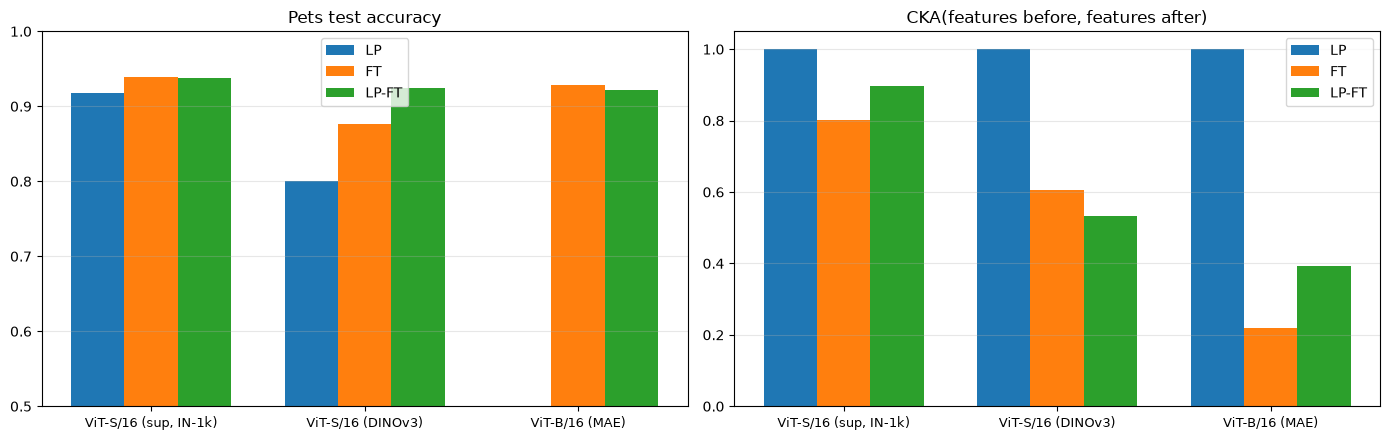

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
modes = ["LP", "FT", "LP-FT"]
width = 0.25
for i, mode in enumerate(modes):
    d = ft_df[ft_df["mode"] == mode].set_index("encoder").loc[FT_ENCODERS]
    axes[0].bar(np.arange(len(FT_ENCODERS)) + (i - 1) * width, d.test_acc, width, label=mode)
    axes[1].bar(np.arange(len(FT_ENCODERS)) + (i - 1) * width, d.cka_to_pretrained, width, label=mode)
for ax, title in zip(axes, ["Pets test accuracy", "CKA(features before, features after)"]):
    ax.set_xticks(np.arange(len(FT_ENCODERS))); ax.set_xticklabels(FT_ENCODERS, fontsize=9)
    ax.set_title(title); ax.grid(alpha=0.3, axis="y"); ax.legend()
axes[0].set_ylim(0.5, 1.0)
plt.tight_layout()
plt.show()

### Takeaways (fine-tuning)

* **MAE flips the ranking:** a poor frozen representation (82% with the L-BFGS probe, 45% with the short in-loop LP) but a great initialization — fine-tuning reaches 93%, on par with the other encoders. Frozen-feature numbers alone would have discarded it.
* **DINOv3:** plain FT (87.7%) is clearly worse than LP-FT (92.4%), and both are below the frozen L-BFGS probe (94.7%). With 3.7k images and 15 epochs, fine-tuning a strong self-supervised encoder from a random head hurts; LP-FT is the safer recipe — and sometimes a frozen probe is simply the best option.
* **Supervised ViT-S:** FT ≈ LP-FT (93.9% / 93.8%), both about 2 points above the frozen probe.
* **Feature change** (CKA to the pretrained features): LP-FT changes the features *less* than FT for the supervised model (0.90 vs 0.80) and for MAE (0.39 vs 0.22), as Kumar et al. predict. For DINOv3 both change them a lot (0.53 vs 0.60), so there the benefit of LP-FT comes from better optimization rather than smaller distortion.
* The in-loop LP (15 epochs of AdamW, timm's default pooling) is far below the converged L-BFGS probe for DINOv3 and MAE: "linear probe" is not one number — always state the recipe.

<a id='Layerwise'></a>
# Where is the information? Layer-wise probing

The last layer is not always the best one to read from. Each block's output is a representation too; a linear probe on every block shows **how the information develops with depth** and whether the last layers are specialized for the pre-training objective (e.g. reconstructing pixels or matching text) rather than for our task.

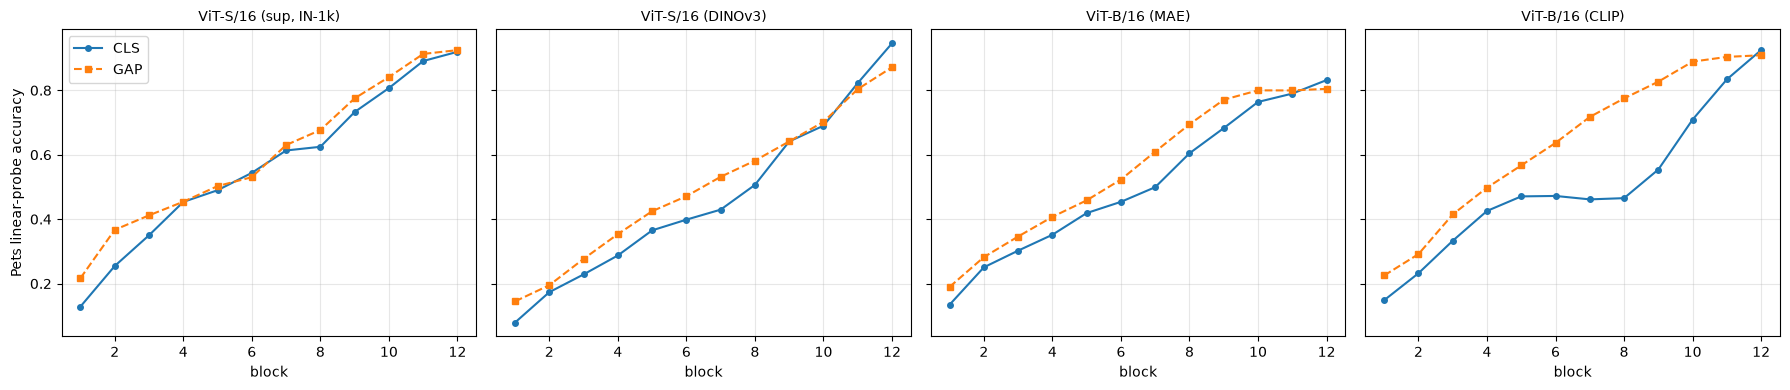

In [17]:
layer_path = os.path.join(RESULTS_DIR, "layerwise_probe.csv")
if RUN_EXPERIMENTS and not os.path.exists(layer_path):   # skip if already computed
    rows = []
    for enc in LAYERWISE_ENCODERS:
        splits = {s: load_feats(enc, "pets", s) for s in ("train", "val", "test")}
        n_layers = splits["train"]["layer_gap"].shape[0]
        for pooling in ("cls", "gap"):
            for layer in range(n_layers):
                xy = lambda s: (splits[s][f"layer_{pooling}"][layer].to(DEVICE), splits[s]["y"].long().to(DEVICE))
                res = linear_probe(xy("train"), xy("val"), xy("test"), 37, weight_decays=(1e-5, 1e-4, 1e-3, 1e-2))
                rows.append({"encoder": enc, "pooling": pooling, "layer": layer + 1, "lp_acc": res["test_acc"]})
    pd.DataFrame(rows).to_csv(layer_path, index=False)
lw = pd.read_csv(layer_path)

fig, axes = plt.subplots(1, len(LAYERWISE_ENCODERS), figsize=(18, 4), sharey=True)
for ax, enc in zip(axes, LAYERWISE_ENCODERS):
    for pooling, style in [("cls", "-o"), ("gap", "--s")]:
        d = lw[(lw.encoder == enc) & (lw.pooling == pooling)]
        ax.plot(d.layer, d.lp_acc, style, markersize=4, label=pooling.upper())
    ax.set_title(enc, fontsize=10); ax.set_xlabel("block"); ax.grid(alpha=0.3)
axes[0].set_ylabel("Pets linear-probe accuracy"); axes[0].legend()
plt.tight_layout()
plt.show()

### Takeaways (layer-wise)

* For all four encoders the information useful for Pets grows steadily with depth (10–20% after block 1) and the **last block is the best one** to probe here.
* Even at its best layer MAE stays ~10 points below the other encoders: its global features are not linearly organized by semantic class, although (as fine-tuning showed) the network can be adapted easily.
* This is not universal — for some objectives and larger models intermediate blocks are better, so the layer-wise curve is worth a few minutes before choosing which features to use.

<a id='Dense'></a>
# Dense probing: what do patch tokens know?

Classification probes only look at one global vector. Segmentation, detection and depth estimation need **spatial** information in the patch tokens. The cheapest test is a **linear probe on every patch token**: the same linear layer classifies each token independently. A linear head cannot "repair" the features — if the pet/background distinction is linearly readable from individual tokens, the dense features are good.

We use the pixel masks of Oxford-IIIT Pets (pet / background / border): the mask is downsampled to the patch grid (majority vote; patches dominated by the uncertain border are ignored). Training uses 1000 trainval images, evaluation 1000 test images; we report the **IoU of the pet class** and the mean IoU over pet and background at patch resolution.

In [18]:
DENSE_ENCODERS = VIT_ENCODERS
dense_path = os.path.join(RESULTS_DIR, "dense_probe.csv")
dense_examples_path = os.path.join(RESULTS_DIR, "dense_probe_examples.npz")


def npz_key(encoder):
    return "pred__" + "".join(ch if ch.isalnum() else "_" for ch in encoder)


def iou(pred, target, cls):
    p, t = pred == cls, target == cls
    return ((p & t).sum() / (p | t).sum()).item()


if RUN_EXPERIMENTS and not os.path.exists(dense_path):   # skip if already computed
    rng = np.random.default_rng(0)
    train_idx = rng.choice(3680, 1000, replace=False)
    test_idx = rng.choice(3669, 1000, replace=False)
    rows, examples = [], {}
    for enc in DENSE_ENCODERS:
        model, tf = load_encoder(enc, DEVICE)
        norm = [t for t in tf.transforms if isinstance(t, T.Normalize)][0]
        tok_tr, m_tr = extract_patch_tokens(model, PetsSegmentation(DATA_DIR, "trainval", norm.mean, norm.std, indices=train_idx), DEVICE)
        tok_te, m_te = extract_patch_tokens(model, PetsSegmentation(DATA_DIR, "test", norm.mean, norm.std, indices=test_idx), DEVICE)
        grid = tok_tr.shape[1]
        lab_tr, lab_te = masks_to_patch_labels(m_tr, grid), masks_to_patch_labels(m_te, grid)
        x_tr, y_tr = tok_tr.flatten(0, 2).float(), lab_tr.flatten()
        keep = y_tr >= 0
        x_tr, y_tr = x_tr[keep].to(DEVICE), y_tr[keep].to(DEVICE)
        x_tr_s, x_te_s = standardize(x_tr, tok_te.flatten(0, 2).float().to(DEVICE))
        clf = fit_logreg(x_tr_s, y_tr, 2, weight_decay=1e-4)
        with torch.no_grad():
            pred_te = clf(x_te_s).argmax(1).reshape(lab_te.shape).cpu()
        valid = lab_te >= 0
        fg, bg = iou(pred_te[valid], lab_te[valid], 1), iou(pred_te[valid], lab_te[valid], 0)
        rows.append({"encoder": enc, "grid": f"{grid}x{grid}", "pet IoU": fg, "mIoU": (fg + bg) / 2})
        examples[enc] = pred_te[:4].numpy().astype(np.uint8)
        print(rows[-1])
        del model
    pd.DataFrame(rows).to_csv(dense_path, index=False)
    # four test images + their masks for the qualitative figure
    vis = PetsSegmentation(DATA_DIR, "test", (0, 0, 0), (1, 1, 1), indices=test_idx[:4])
    imgs = np.stack([(vis[i][0].permute(1, 2, 0).numpy() * 255).astype(np.uint8) for i in range(4)])
    masks = np.stack([vis[i][1].numpy().astype(np.int8) for i in range(4)])
    np.savez_compressed(dense_examples_path, images=imgs, masks=masks,
                        **{npz_key(k): v for k, v in examples.items()})

dense_df = pd.read_csv(dense_path)
dense_df.style.format({"pet IoU": "{:.1%}", "mIoU": "{:.1%}"}).background_gradient(subset=["mIoU"], cmap="Purples")

,encoder,grid,pet IoU,mIoU
0,Random ViT-S/16,14x14,34.2%,50.5%
1,"ViT-S/16 (sup, IN-1k)",14x14,88.6%,91.1%
2,"ViT-S/16 (sup, IN-21k)",14x14,90.2%,92.4%
3,ViT-S/16 (DINO),14x14,94.2%,95.5%
4,ViT-S/14 (DINOv2-reg),16x16,95.4%,96.4%
5,ViT-S/16 (DINOv3),14x14,96.5%,97.3%
6,ViT-B/16 (MAE),14x14,95.9%,96.8%
7,ViT-B/16 (CLIP),14x14,90.7%,92.8%


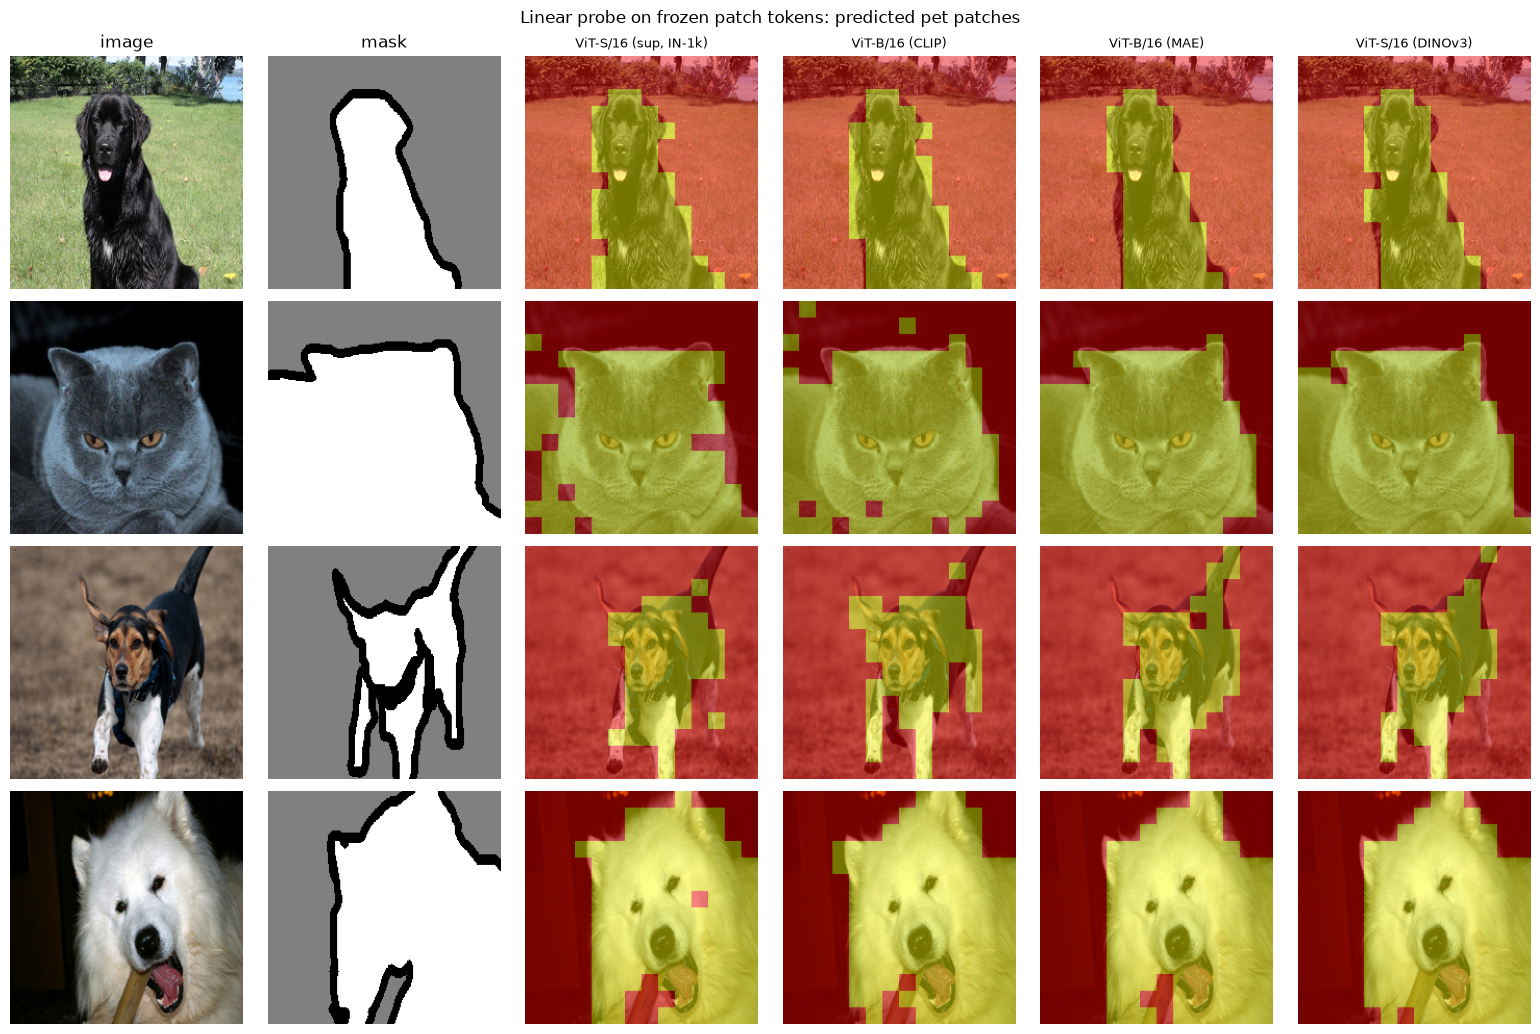

In [19]:
ex = np.load(dense_examples_path)
show = ["ViT-S/16 (sup, IN-1k)", "ViT-B/16 (CLIP)", "ViT-B/16 (MAE)", "ViT-S/16 (DINOv3)"]
fig, axes = plt.subplots(4, 2 + len(show), figsize=(2.6 * (2 + len(show)), 10.5))
for i in range(4):
    axes[i, 0].imshow(ex["images"][i]); axes[i, 0].set_title("image" if i == 0 else "")
    axes[i, 1].imshow(ex["masks"][i], cmap="gray", vmin=-1, vmax=1); axes[i, 1].set_title("mask" if i == 0 else "")
    for j, enc in enumerate(show):
        pred = ex[npz_key(enc)][i]
        axes[i, 2 + j].imshow(ex["images"][i])
        axes[i, 2 + j].imshow(np.kron(pred, np.ones((224 // pred.shape[0],) * 2)), cmap="autumn", alpha=0.45, vmin=0, vmax=1)
        if i == 0:
            axes[i, 2 + j].set_title(enc, fontsize=9)
for ax in axes.flatten():
    ax.axis("off")
plt.suptitle("Linear probe on frozen patch tokens: predicted pet patches")
plt.tight_layout()
plt.show()

### Takeaways (dense probing)

* **The dense ranking differs from the global one.** MAE, nearly useless under k-NN, has excellent patch tokens (95.9% pet IoU): its objective is to reconstruct every patch from its context, so each token must describe its own region.
* **DINOv3 is the best** (96.5% pet IoU), followed by MAE, DINOv2 and DINO. CLIP (90.7%) and the supervised models (88.6–90.2%) localize the pet clearly worse: image-level objectives do not force every patch to carry local semantics.
* Random features already reach 34% pet IoU from colour and texture cues alone — always report a baseline.

<a id='Visualization'></a>
# Looking at embeddings: PCA and t-SNE

Pictures of embedding spaces are the most popular and the most misused evaluation tool.

* **PCA** is a linear projection onto the directions of largest variance. Distances and cluster sizes are faithful, but two dimensions usually capture only a small part of the variance, so classes overlap.
* **t-SNE** (and UMAP) is a non-linear method that tries to keep each point's **nearest neighbours** close in 2D. It is great at showing local cluster structure, but:
  * the **sizes** of clusters and the **distances between** clusters are mostly meaningless;
  * the result depends on the **perplexity** (roughly, how many neighbours each point "cares about") and on the random seed;
  * it can make clusters look cleaner than they are. Use it to *illustrate* a quantitative result (k-NN accuracy), not to replace it.

Standard practice: reduce to 50 dimensions with PCA first, then run t-SNE. Pets test set, colours = breed; circles are cats, triangles are dogs.

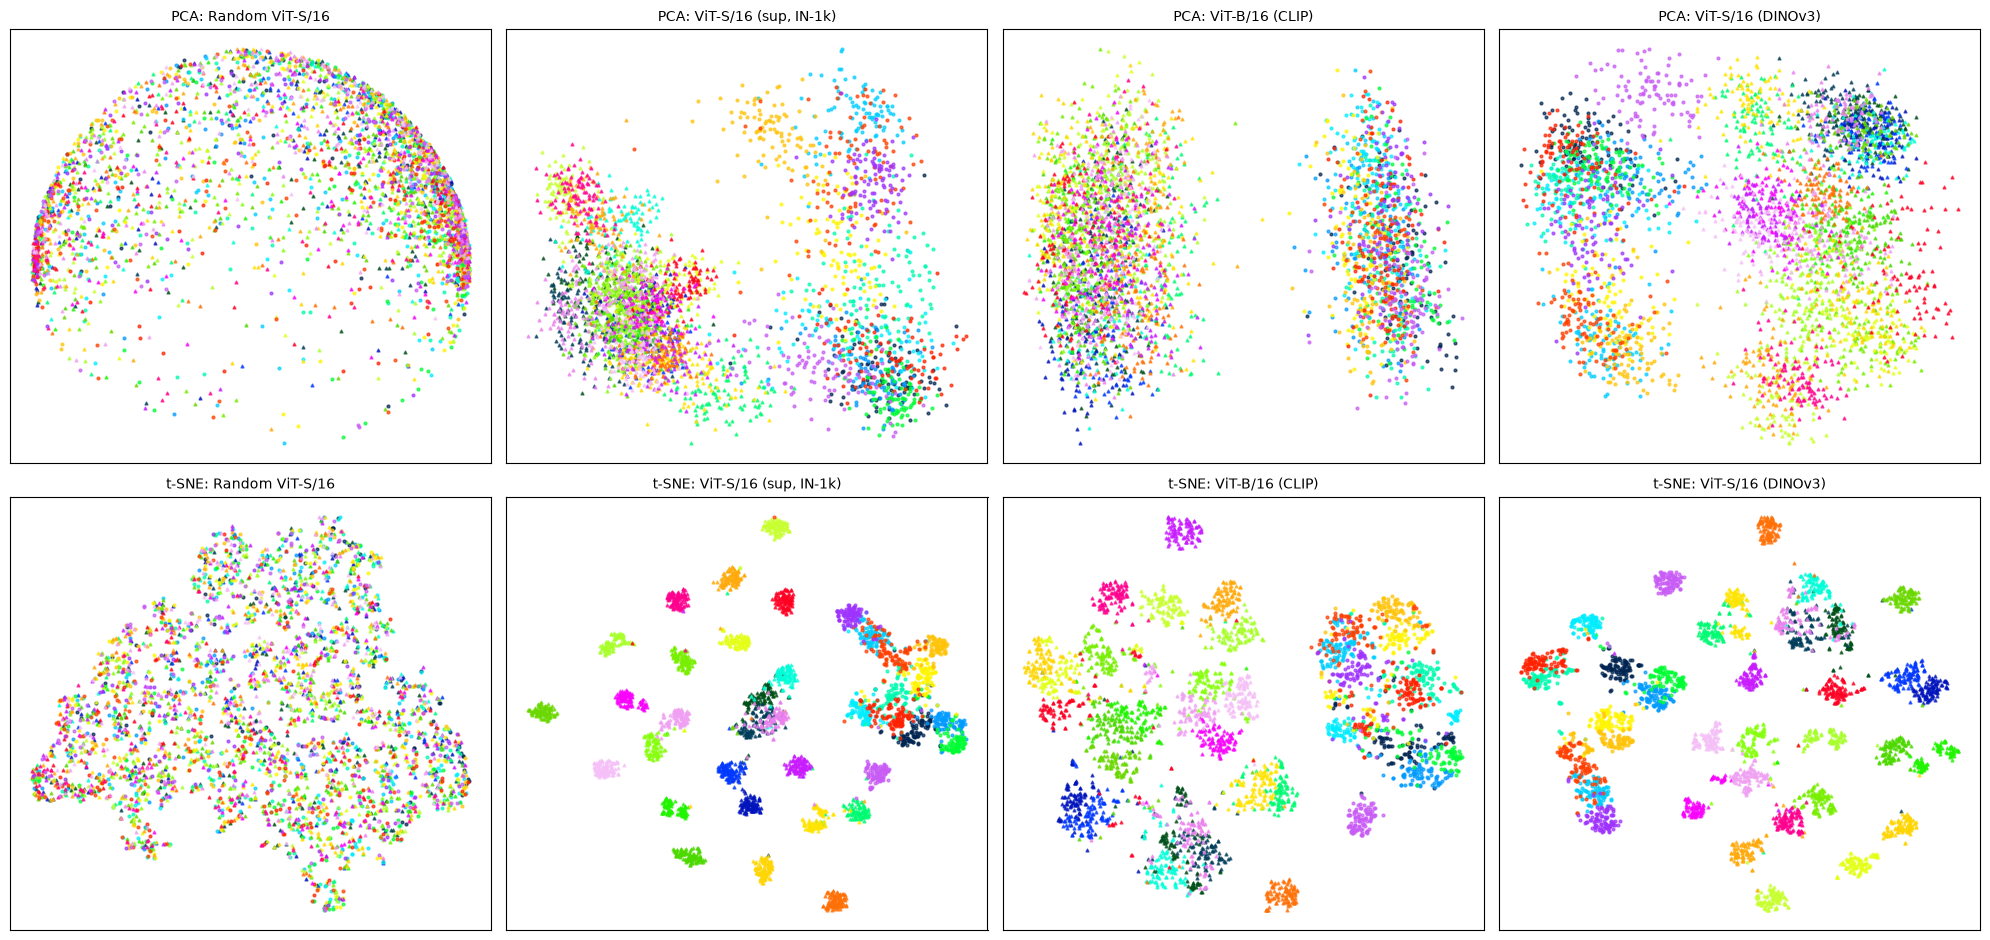

In [20]:
CAT_BREEDS = {"abyssinian", "bengal", "birman", "bombay", "british_shorthair", "egyptian_mau", "maine_coon",
              "persian", "ragdoll", "russian_blue", "siamese", "sphynx"}
TSNE_ENCODERS = ["Random ViT-S/16", "ViT-S/16 (sup, IN-1k)", "ViT-B/16 (CLIP)", "ViT-S/16 (DINOv3)"]
tsne_path = os.path.join(RESULTS_DIR, "tsne_pets.csv")


def tsne_2d(x, perplexity=30, seed=0):
    # one thread for scikit-learn: avoids an OpenMP deadlock between the torch and scikit-learn runtimes
    with threadpool_limits(limits=1):
        x = PCA(n_components=50, random_state=seed).fit_transform(x)
        return TSNE(n_components=2, perplexity=perplexity, init="pca", random_state=seed).fit_transform(x)


if RUN_EXPERIMENTS and not os.path.exists(tsne_path):   # skip if already computed
    pet_classes = build_dataset("pets", "test", None, DATA_DIR).classes
    rows = []
    for enc in TSNE_ENCODERS:
        x, y = get_split(enc, "pets", "test", device="cpu")
        perplexities = [5, 30, 100] if enc == "ViT-S/16 (DINOv3)" else [30]
        for p in perplexities:
            xy = tsne_2d(x.numpy(), perplexity=p)
            rows.append(pd.DataFrame({"encoder": enc, "perplexity": p, "x": xy[:, 0], "y": xy[:, 1],
                                      "label": y.numpy(), "breed": [pet_classes[i] for i in y.numpy()]}))
        with threadpool_limits(limits=1):
            pca = PCA(n_components=2).fit_transform(x.numpy())
        rows.append(pd.DataFrame({"encoder": enc, "perplexity": -1, "x": pca[:, 0], "y": pca[:, 1],
                                  "label": y.numpy(), "breed": [pet_classes[i] for i in y.numpy()]}))
    pd.concat(rows).to_csv(tsne_path, index=False)
tsne_df = pd.read_csv(tsne_path)


def scatter(ax, d, title):
    colors = plt.cm.gist_ncar(np.linspace(0.02, 0.95, 37))
    for lab in range(37):
        dd = d[d.label == lab]
        marker = "o" if dd.breed.iloc[0].lower().replace(" ", "_") in CAT_BREEDS else "^"
        ax.scatter(dd.x, dd.y, s=4, color=colors[lab], marker=marker, alpha=0.7)
    ax.set_title(title, fontsize=10); ax.set_xticks([]); ax.set_yticks([])


fig, axes = plt.subplots(2, len(TSNE_ENCODERS), figsize=(5 * len(TSNE_ENCODERS), 9.5))
for j, enc in enumerate(TSNE_ENCODERS):
    scatter(axes[0, j], tsne_df[(tsne_df.encoder == enc) & (tsne_df.perplexity == -1)], f"PCA: {enc}")
    scatter(axes[1, j], tsne_df[(tsne_df.encoder == enc) & (tsne_df.perplexity == 30)], f"t-SNE: {enc}")
plt.tight_layout()
plt.show()

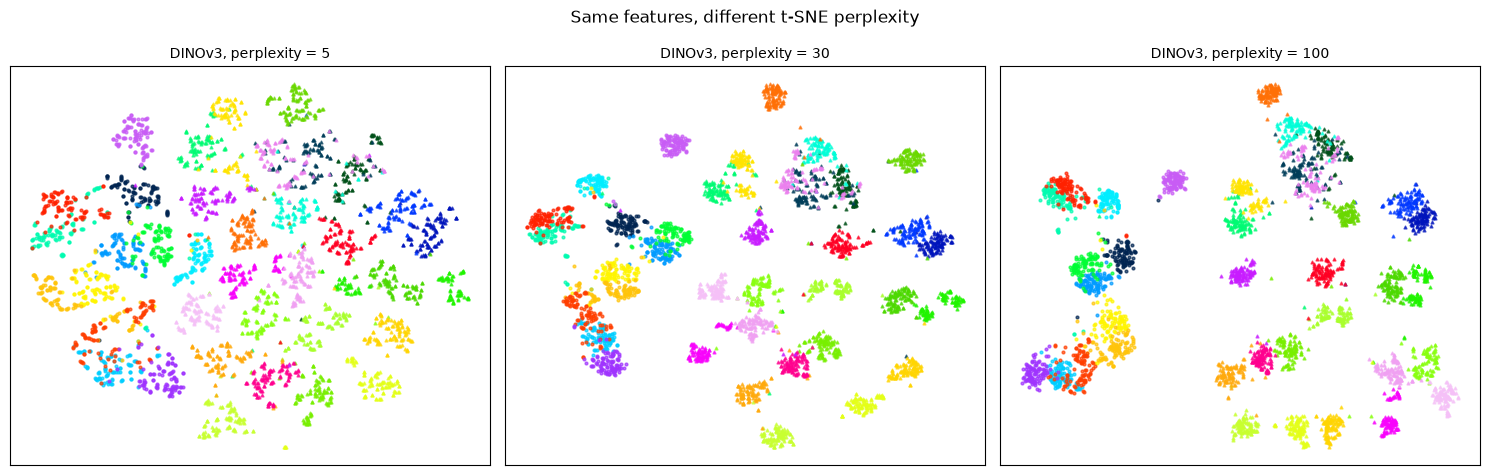

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, p in zip(axes, [5, 30, 100]):
    scatter(ax, tsne_df[(tsne_df.encoder == "ViT-S/16 (DINOv3)") & (tsne_df.perplexity == p)], f"DINOv3, perplexity = {p}")
plt.suptitle("Same features, different t-SNE perplexity")
plt.tight_layout()
plt.show()

### Takeaways (visualization)

* PCA mostly shows a coarse split into a few large groups; t-SNE reveals per-breed clusters for the supervised, CLIP and DINOv3 encoders and no structure for the random network — consistent with their k-NN accuracy.
* Changing the perplexity changes the size and the separation of the clusters while the features stay exactly the same: t-SNE pictures illustrate a quantitative result, they do not replace it.

<a id='Label_Free'></a>
# Label-free diagnostics: effective rank and CKA

Sometimes we have **no labels** for the target task (e.g. choosing a checkpoint during self-supervised pre-training, or comparing encoders before annotating anything). Two simple tools need only the embeddings.

## Effective rank (RankMe)

If all embeddings lie close to a few directions, the representation has "collapsed" — it can distinguish only a few factors of variation. Take the matrix $Z \in \mathbb{R}^{N \times D}$ of embeddings, its singular values $\sigma_1 \ge \dots \ge \sigma_D$, normalize them into a distribution $p_k = \sigma_k / \sum_j \sigma_j$, and compute

$$
\mathrm{RankMe}(Z) = \exp\Big(-\sum_k p_k \log p_k\Big) \in [1, D].
$$

It equals $D$ if all directions are used equally and 1 if everything lies on a line. Garrido et al. showed that, **within one family of models**, a higher effective rank predicts better downstream accuracy without any labels. Across very different models and dimensions the relation is much weaker — let's see.

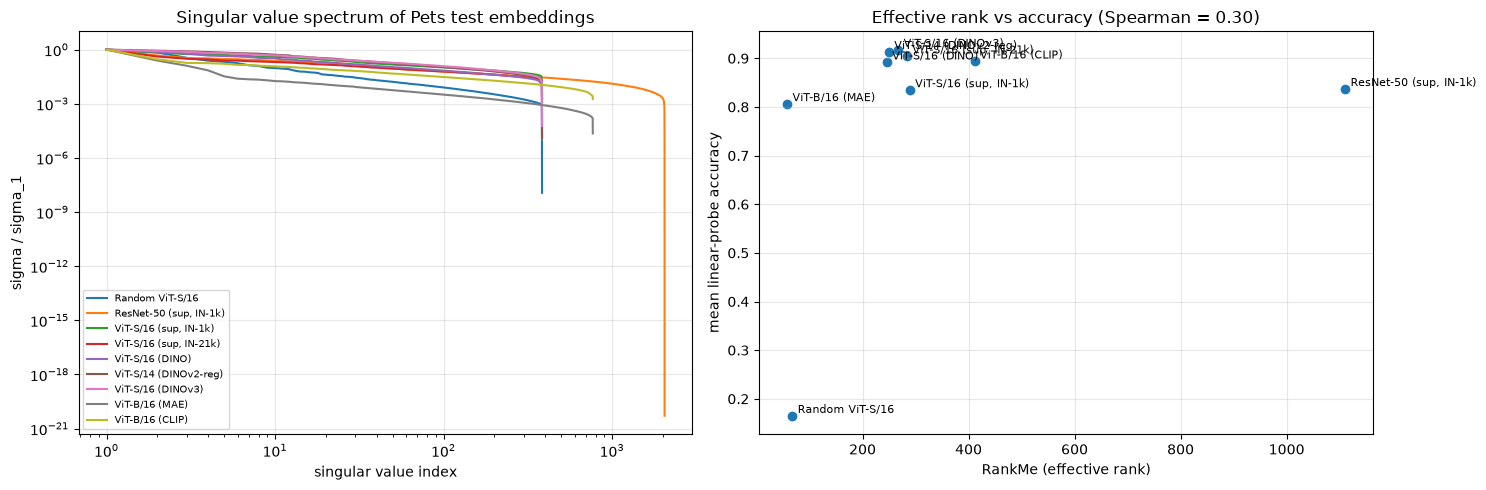

,encoder,dim,RankMe,RankMe / dim,mean LP acc (3 datasets)
0,Random ViT-S/16,384,67.166,0.175,0.165
1,"ResNet-50 (sup, IN-1k)",2048,1110.224,0.542,0.837
2,"ViT-S/16 (sup, IN-1k)",384,288.656,0.752,0.835
3,"ViT-S/16 (sup, IN-21k)",384,283.765,0.739,0.904
4,ViT-S/16 (DINO),384,245.570,0.640,0.892
5,ViT-S/14 (DINOv2-reg),384,249.306,0.649,0.913
6,ViT-S/16 (DINOv3),384,267.023,0.695,0.918
7,ViT-B/16 (MAE),768,57.401,0.075,0.806
8,ViT-B/16 (CLIP),768,411.176,0.535,0.894


In [22]:
def rankme(z, eps=1e-7):
    s = torch.linalg.svdvals(z.double())
    p = s / s.sum() + eps
    return torch.exp(-(p * p.log()).sum()).item()


rank_path = os.path.join(RESULTS_DIR, "rankme.csv")
spectra_path = os.path.join(RESULTS_DIR, "singular_value_spectra.csv")
if RUN_EXPERIMENTS and not os.path.exists(rank_path):   # skip if already computed
    rows, spectra = [], []
    for enc in ENCODERS:
        z, _ = get_split(enc, "pets", "test", device="cpu")
        s = torch.linalg.svdvals(z.double())
        rows.append({"encoder": enc, "dim": z.shape[1], "RankMe": rankme(z), "RankMe / dim": rankme(z) / z.shape[1]})
        spectra.append(pd.DataFrame({"encoder": enc, "index": np.arange(1, len(s) + 1), "sigma": (s / s[0]).numpy()}))
    pd.DataFrame(rows).to_csv(rank_path, index=False)
    pd.concat(spectra).to_csv(spectra_path, index=False)
rank_df = pd.read_csv(rank_path)
spec = pd.read_csv(spectra_path)
mean_lp = lp_df.groupby("encoder").lp_acc.mean()
rank_df["mean LP acc (3 datasets)"] = rank_df.encoder.map(mean_lp)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for enc in ENCODERS:
    d = spec[spec.encoder == enc]
    axes[0].plot(d["index"], d.sigma, label=enc)
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_xlabel("singular value index"); axes[0].set_ylabel("sigma / sigma_1"); axes[0].legend(fontsize=7)
axes[0].set_title("Singular value spectrum of Pets test embeddings"); axes[0].grid(alpha=0.3)
axes[1].scatter(rank_df.RankMe, rank_df["mean LP acc (3 datasets)"])
for _, r in rank_df.iterrows():
    axes[1].annotate(r.encoder, (r.RankMe, r["mean LP acc (3 datasets)"]), fontsize=8, xytext=(4, 2), textcoords="offset points")
rho = spearmanr(rank_df.RankMe, rank_df["mean LP acc (3 datasets)"]).correlation
axes[1].set_xlabel("RankMe (effective rank)"); axes[1].set_ylabel("mean linear-probe accuracy")
axes[1].set_title(f"Effective rank vs accuracy (Spearman = {rho:.2f})"); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()
rank_df.round(3)

## Comparing representations: linear CKA

How similar are two representations of the same images? We cannot compare the vectors directly — the dimensions of two models are unrelated, and even the same model trained twice produces rotated features. **Centered Kernel Alignment** compares the *similarity structure* instead: do the two models agree on which images are similar to each other? For centered feature matrices $X \in \mathbb{R}^{N \times D_1}$, $Y \in \mathbb{R}^{N \times D_2}$:

$$
\mathrm{CKA}(X, Y) = \frac{\lVert Y^\top X \rVert_F^2}{\lVert X^\top X \rVert_F\, \lVert Y^\top Y \rVert_F} \in [0, 1].
$$

It is invariant to rotations and to isotropic scaling of either representation, works for different dimensions, and equals 1 for identical representations (we already used it to measure feature distortion in fine-tuning). Rows and columns of the heatmap are ordered by hierarchical clustering (single linkage on $1 - |\mathrm{CKA}|$), so groups of similar encoders form blocks on the diagonal.

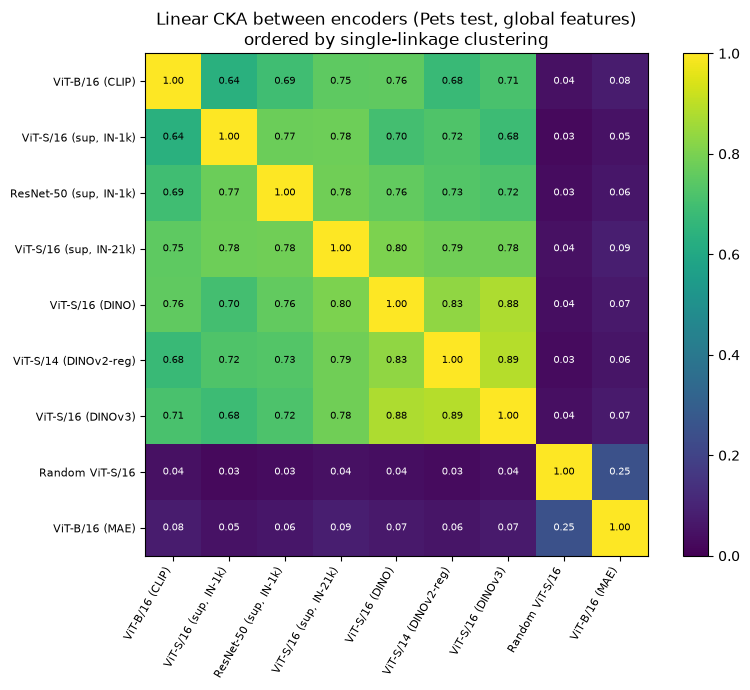

In [23]:
cka_path = os.path.join(RESULTS_DIR, "cka_encoders.csv")
if RUN_EXPERIMENTS and not os.path.exists(cka_path):   # skip if already computed
    feats = {enc: get_split(enc, "pets", "test", device="cpu")[0] for enc in ENCODERS}
    mat = pd.DataFrame([[linear_cka(feats[a], feats[b]) for b in ENCODERS] for a in ENCODERS],
                       index=list(ENCODERS), columns=list(ENCODERS))
    mat.to_csv(cka_path)
cka_mat = pd.read_csv(cka_path, index_col=0)


def cluster_order(sim):
    """Heatmap order from single-linkage clustering on distance 1 - |similarity|: repeatedly merge the most
    similar pair; a group's similarity to another item is the maximum over its members."""
    d = 1 - np.abs(np.asarray(sim, dtype=float))
    d = (d + d.T) / 2
    np.fill_diagonal(d, 0)
    return leaves_list(linkage(squareform(d, checks=False), method="single"))


order = cluster_order(cka_mat.values)
cka_mat = cka_mat.iloc[order, order]

fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(cka_mat.values, cmap="viridis", vmin=0, vmax=1)
ax.set_xticks(range(len(cka_mat))); ax.set_xticklabels(cka_mat.columns, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(cka_mat))); ax.set_yticklabels(cka_mat.index, fontsize=8)
for i in range(len(cka_mat)):
    for j in range(len(cka_mat)):
        ax.text(j, i, f"{cka_mat.values[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if cka_mat.values[i, j] < 0.6 else "black")
plt.colorbar(im, fraction=0.046)
ax.set_title("Linear CKA between encoders (Pets test, global features)\nordered by single-linkage clustering")
plt.tight_layout()
plt.show()

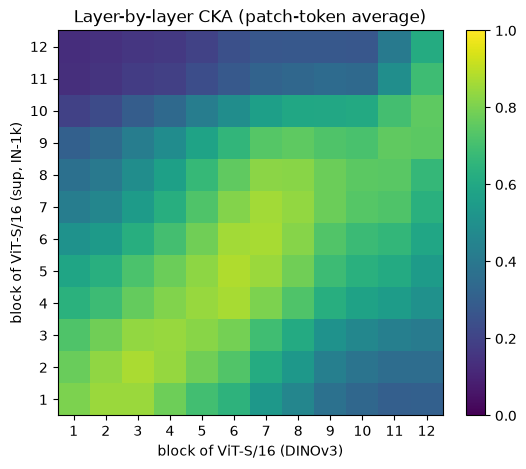

In [24]:
cka_layers_path = os.path.join(RESULTS_DIR, "cka_layers.csv")
A, B = "ViT-S/16 (sup, IN-1k)", "ViT-S/16 (DINOv3)"
if RUN_EXPERIMENTS and not os.path.exists(cka_layers_path):   # skip if already computed
    fa, fb = load_feats(A, "pets", "test")["layer_gap"], load_feats(B, "pets", "test")["layer_gap"]
    pd.DataFrame([[linear_cka(fa[i], fb[j]) for j in range(len(fb))] for i in range(len(fa))]).to_csv(cka_layers_path, index=False)
cka_layers = pd.read_csv(cka_layers_path).values

plt.figure(figsize=(6, 5))
plt.imshow(cka_layers, cmap="viridis", vmin=0, vmax=1, origin="lower")
plt.colorbar(fraction=0.046)
plt.xlabel(f"block of {B}"); plt.ylabel(f"block of {A}")
plt.xticks(range(12), range(1, 13)); plt.yticks(range(12), range(1, 13))
plt.title("Layer-by-layer CKA (patch-token average)")
plt.show()

### Takeaways (label-free diagnostics)

* **MAE has by far the lowest effective rank** among the pretrained encoders (57 of 768): its global embedding is dominated by a few directions. This is why cosine k-NN fails on it while a linear probe on standardized features works.
* **Across model families the effective rank barely predicts accuracy** (Spearman ≈ 0.3 with the random network, ≈ 0 without it): the supervised ViT-S has a higher rank than DINOv3 but lower accuracy. RankMe is a tool for comparing checkpoints of the *same* model, not different models.
* **CKA between encoders:** the DINO family is mutually similar (0.83–0.89), the supervised and CLIP models form a looser group (0.64–0.80), and MAE is unlike all of them (≤ 0.09). Its CKA to the *random* network (0.25) is even higher — linear CKA is dominated by the few high-variance directions, which for MAE carry little semantics.
* **Layer by layer**, the supervised and DINOv3 ViT-S are similar in early and middle blocks (CKA ≈ 0.8–0.86) and diverge in the last blocks (≈ 0.5–0.6): early layers learn generic features whatever the objective; the last layers are objective-specific.

<a id='Pitfalls'></a>
# Pitfalls, benchmarks, and how to choose a protocol

## Pitfalls that silently change the numbers

| Pitfall | What goes wrong | Do instead |
|---|---|---|
| **Tuning on the test set** | choosing $k$, weight decay, pooling or the epoch by test accuracy inflates it | select on a validation split, report test once |
| **Different preprocessing** | resolution, crop ratio, normalization differ between checkpoints | use each checkpoint's own normalization, the same resolution for all |
| **Pooling choice** | the patch average of a DINO-family model is up to ~18 points worse than its [CLS] (we saw it on Pets) | report the pooling; try [CLS], average, concat on validation |
| **Different recipes** | L-BFGS vs SGD with augmentation, BatchNorm before the head, number of epochs | compare models only under one recipe |
| **Model size and compute** | a ViT-B vs a ViT-S is not an architecture comparison | compare at equal size / FLOPs, or say so |
| **Pre-training data / label overlap** | the downstream images (or near-duplicates, or the same classes) were in the pre-training data — our ImageNet-21k ViT-S gets 99.7% linear on Flowers vs 88% for the ImageNet-1k version | deduplicate, or at least acknowledge |
| **Imbalanced classes** | accuracy hides failure on rare classes | balanced accuracy, macro-F1, per-class recall, mAP |
| **Noise** | few-shot sampling, small test sets, seeds | several seeds, confidence intervals |

## Standard benchmarks you will see in papers

* **ImageNet k-NN and linear probe** — the classic frozen-feature numbers (DINO, DINOv2/v3, MAE, CLIP papers).
* **VTAB-1k** — 19 diverse tasks (natural, specialized such as medical or satellite, structured such as counting or depth), only 1000 training images each.
* **Fine-grained transfer** — Pets, Flowers, Cars, Aircraft, Food, iNaturalist.
* **Dense tasks with frozen features** — linear segmentation on ADE20K / Pascal VOC, depth on NYUv2 — the main evaluation of DINOv2/v3.
* **Retrieval and robustness** — Oxford / Paris landmarks; ImageNet-A / -R / -Sketch for distribution shift.

## How to choose a protocol

| Your situation | Protocol to trust |
|---|---|
| Comparing many encoders quickly, no training budget | k-NN + linear probe on your data (cache features once) |
| Few labels per class | few-shot linear / k-NN curves |
| You will fine-tune anyway and have enough data | short fine-tuning runs (FT and LP-FT) on your data — frozen numbers can mislead (MAE), and FT can underperform a frozen probe (DINOv3) |
| Segmentation / detection downstream | dense probe on patch tokens, not classification probes |
| No labels at all | effective rank, CKA to a known-good model, visual inspection — as a rough filter only |

<a id='Summary'></a>
# Summary

* A representation is evaluated by **what we put on top of it**: nothing (k-NN), a linear layer (linear probe, dense probe), few labels (few-shot), or full adaptation (fine-tuning). Each protocol answers a different question, and they can **rank encoders differently**.
* **k-NN** measures the neighbourhood structure and is sensitive to geometry; the **linear probe** measures linear separability and needs a clean protocol (standardization, validation-selected regularization, report test once).
* **Fine-tuning** measures quality as an initialization; it can flip the frozen-feature ranking (MAE) and can even underperform a frozen probe (DINOv3). **LP-FT** trains the head first and is the safer recipe; it often (not always) changes the backbone's features less.
* The information is not always in the last layer or in the [CLS] token: **pooling and layer choice** can change conclusions.
* **Dense probes** on patch tokens evaluate spatial information that global probes cannot see.
* **t-SNE** illustrates neighbourhoods but distorts global geometry; **effective rank** and **CKA** are label-free diagnostics, useful as rough filters and for comparing models.

# Self-check questions

**Theory**
1. What does a k-NN classifier on frozen features measure, and why is it sensitive to the geometry of the embedding space? Why do we L2-normalize the embeddings?
2. Describe a correct linear-probe protocol. Why is it wrong to choose the weight decay on the test set? Why do we standardize the features?
3. Give an example where the k-NN / linear-probe ranking of two encoders disagrees with their fine-tuning ranking, and explain why that can happen.
4. What is feature distortion in fine-tuning, and how does LP-FT reduce it?
5. Why can the average of the patch tokens be a better global representation than the [CLS] token? When is the opposite true?
6. What does a dense (patch-level) linear probe measure that a global linear probe cannot?
7. What can and cannot be concluded from a t-SNE plot? What does the perplexity control?
8. Define RankMe. Why is a collapsed representation bad, and why is RankMe only a rough predictor across different model families?
9. Define linear CKA. Why can't we compare two representations by the distance between their vectors directly?

**Practice**
1. Implement weighted k-NN classification (cosine similarity, top-$k$, temperature) for a test batch without loops over training examples.
2. You have 9 encoders, 5 labelled images per class and a GPU for one hour. Design the evaluation and say which numbers you would report.
3. An encoder gets 90% with a linear probe on [CLS] and 60% with k-NN. List three possible reasons and how you would check each.
4. Compute RankMe for embeddings whose singular values are $(4, 2, 1, 1)$. What is the maximum possible value for $D = 4$?
5. Your segmentation model must run on 1024×1024 images. Which evaluation of candidate backbones would you run before fine-tuning any of them?